[[0.99830872 0.        ]
 [0.016      1.        ]]


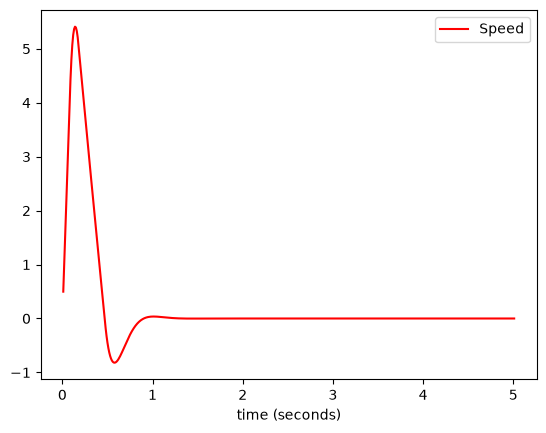

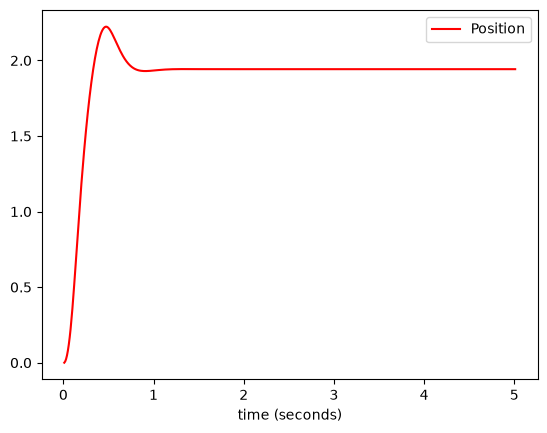

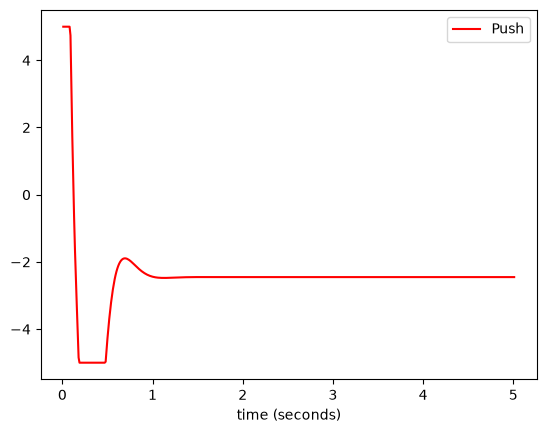

In [15]:
#
# to be tested with godot/Multirotor
#

import numpy as np
import arslabrobotics as ar
import scipy.optimize as opt

class MPC_Drone_Z:

    def __init__(self):
        # model identified using least-square method
        (a, b) = ([-0.998308720394236], [0.06676269003659396])
        
        # Discrete system model
        s = ar.identification.ARXModel(a, b)
        (A, B, C) = s.state_space()
        
        #print(A, B, C)
        
        # resize the matrices in order to add position as state variable
        A = np.hstack( (A, np.zeros( (1,1) ) ) )
        A = np.vstack( (A, np.zeros( (1,2) ) ) )
        B = np.vstack( (B, [0]) )

        delta_t = 0.016
        
        A[1,0] = delta_t
        A[1,1] = 1.0

        self.A = A
        self.B = B
        
        self.Q = np.array([0.0, 10.0])  # Peso alto su errore posizione, basso su velocità
        self.R = 0.1                     # Peso sull'azione di controllo (energia)
        self.N = 30
        self.target = np.array([0.0, 0.0])
        self.delta_t = delta_t
        self.initial_state = [0.0, 0.0]
        
        # Vincoli fisici sulla spinta del motore (es. max +-25 Newton)
        self.max_force = 5.0

    def set_target(self, vz, z):
        self.target = np.array([ [vz] ,[ z] ])

    def opt_fun(self, u_array):
        #print(u_array)
        vz = self.initial_state[0]
        z = self.initial_state[1]
        total_cost = 0
        x = np.array([[vz], [z]])
        for i in range(self.N):
            u = u_array[i]
            
            # compute error
            err = self.target - x
            #print(err[0,0], err[1,0])
            
            # quadratic cost function: J = x^T*Q*x + u^T*R*u
            cost = (self.Q[0] * (err[0,0] ** 2)) + (self.Q[1] * (err[1,0] ** 2)) + (self.R * (u ** 2))
            total_cost += cost

            x = self.A @ x + self.B * [u + 9.81/4]
             
        #print(total_cost)
        return total_cost

    def optimize(self, delta_t, initial_u, vz, z):
        self.initial_state = [vz, z]
        self.delta_t = delta_t

        # Initial vector based on last command 
        u_init = np.array([initial_u] * self.N)
        
        # Bounds of the input (saturation)
        bounds = opt.Bounds([-self.max_force] * self.N, [self.max_force] * self.N)
        
        result = opt.minimize(self.opt_fun, u_init, method='SLSQP', bounds=bounds)
        #print(result)
        return result.x
            

spd = ar.data.DataPlotter()
spd.set_x("time (seconds)")
spd.add_y("speed", "Speed")

pos = ar.data.DataPlotter()
pos.set_x("time (seconds)")
pos.add_y("pos", "Position")

push = ar.data.DataPlotter()
push.set_x("time (seconds)")
push.add_y("push", "Push")

ctrl = MPC_Drone_Z()
ctrl.set_target(0, 2.0)


# model identified using least-square method
(a, b) = ([-0.998308720394236], [0.06676269003659396])

# Discrete system model
drone = ar.identification.ARXModel(a, b)
(A, B, C) = drone.state_space()
# resize the matrices in order to add position as state variable
A = np.hstack( (A, np.zeros( (1,1) ) ) )
A = np.vstack( (A, np.zeros( (1,2) ) ) ) 
B = np.vstack( (B, [0]) )

A[1,0] = ctrl.delta_t
A[1,1] = 1.0
print(A)
#ctrl.optimize(0.1, 100, 0, 0)


t = ar.utils.Time(use_fake_time=True)
t.start()
force = 1
x = np.array( [[0], [0]])

while t.get() < 5:

    t.sleep(0.01)
    delta_t = t.elapsed()

    force_array = ctrl.optimize(delta_t, force, x[0,0], x[1,0])
    
    force = force_array[0]

    x = A @ x + B * [force + 9.81/4]
    
    spd.append_x(t.get())
    spd.append_y("speed", x[0,0])
    
    pos.append_x(t.get())
    pos.append_y("pos", x[1,0])

    push.append_x(t.get())
    push.append_y("push", force)
    
spd.plot()
pos.plot()
push.plot()